In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib

print("SHAP libraries imported successfully!")

SHAP libraries imported successfully!


In [2]:
X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")

y_train = pd.read_csv("../data/y_train.csv").squeeze()
y_test = pd.read_csv("../data/y_test.csv").squeeze()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (614, 8)
X_test shape: (154, 8)


In [3]:
xgb_model = joblib.load("../models/xgboost.pkl")

print("XGBoost model loaded successfully!")

XGBoost model loaded successfully!


In [4]:
explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [5]:
shap_values = explainer(X_test)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


In [6]:
print(shap_values.shape)

(154, 8)


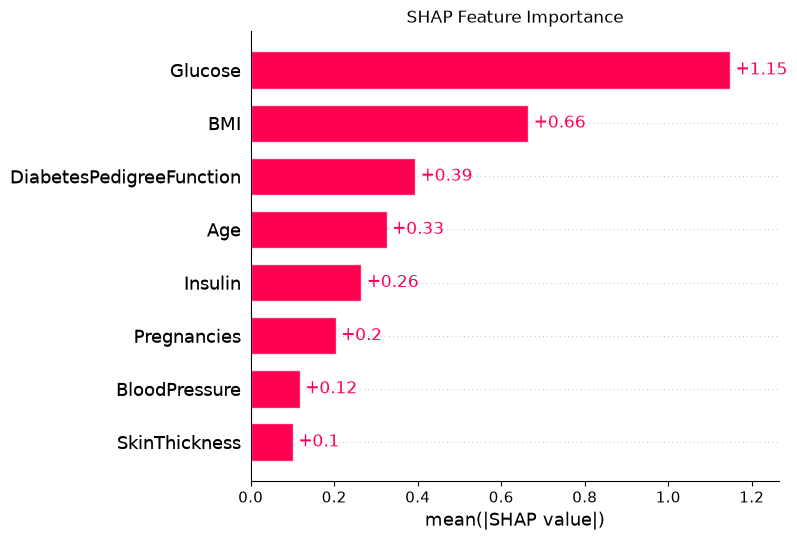

In [7]:
plt.figure()

shap.plots.bar(shap_values, max_display=8, show=False)

plt.title("SHAP Feature Importance")
plt.tight_layout()

plt.savefig("../results/figures/shap_feature_importance.png", dpi=300)

plt.show()

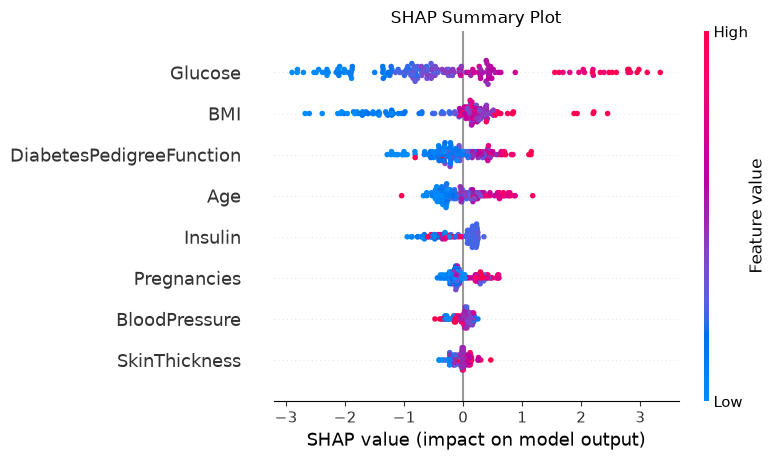

In [8]:
plt.figure()

shap.summary_plot(
    shap_values.values,
    X_test,
    show=False
)

plt.title("SHAP Summary Plot")
plt.tight_layout()

plt.savefig("../results/figures/shap_summary.png", dpi=300)

plt.show()

In [9]:
patient_index = 0

print(X_test.iloc[patient_index])

Pregnancies                 0.960541
Glucose                     1.245157
BloodPressure              -0.663676
SkinThickness              -0.004766
Insulin                    -0.161437
BMI                        -0.740363
DiabetesPedigreeFunction   -0.555791
Age                         0.561034
Name: 0, dtype: float64


In [10]:
prediction = xgb_model.predict(
    X_test.iloc[[patient_index]]
)[0]

probability = xgb_model.predict_proba(
    X_test.iloc[[patient_index]]
)[0][1]

print("Prediction:", prediction)
print("Diabetes probability:", probability)

Prediction: 1
Diabetes probability: 0.8917195


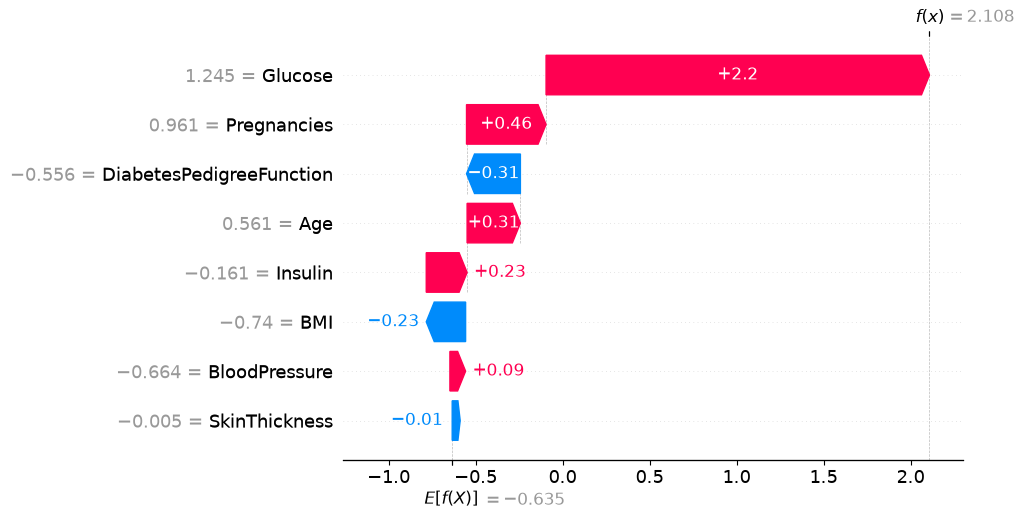

In [11]:
shap.plots.waterfall(
    shap_values[patient_index],
    max_display=8
)

In [12]:
shap_df = pd.DataFrame(
    shap_values.values,
    columns=X_test.columns
)

shap_df.to_csv(
    "../results/shap_values.csv",
    index=False
)

print("SHAP values saved successfully!")

SHAP values saved successfully!
